<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving study_hours_marks.csv to study_hours_marks.csv
DATASET:
    Study_Hours  Marks
0             1     35
1             2     40
2             3     50
3             4     55
4             5     65
5             6     70
6             7     75
7             8     85
8             9     88
9            10     95
10           11     98
11           12    100

Predicted Marks:
[98.87150838 92.78212291 37.97765363]

Mean Absolute Error:
2.022346368715086

Mean Squared Error:
4.84830893750718

R2 Score:
0.9942419133758822

Predicted Marks for 8 Study Hours:
[80.60335196]


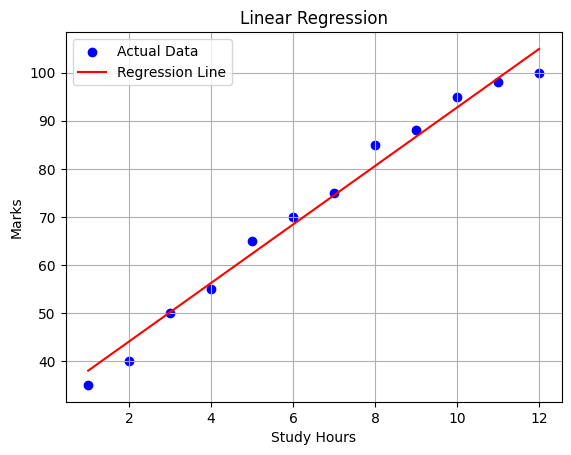

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Input and output
X = data[["Study_Hours"]]
y = data["Marks"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("\nPredicted Marks:")
print(y_pred)

print("\nMean Absolute Error:")
print(mean_absolute_error(y_test, y_pred))

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))

# Predict marks for a new student
new_student = pd.DataFrame({
    "Study_Hours": [8]
})

print("\nPredicted Marks for 8 Study Hours:")
print(model.predict(new_student))

# Plot regression line
x_line = pd.DataFrame({
    "Study_Hours": range(
        int(X["Study_Hours"].min()),
        int(X["Study_Hours"].max()) + 1
    )
})

plt.scatter(X, y, color="blue", label="Actual Data")

plt.plot(
    x_line,
    model.predict(x_line),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear Regression")
plt.legend()
plt.grid()
plt.show()